In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from itertools import combinations
from collections import Counter
from sklearn.linear_model import LinearRegression

# Load and save data from CSV

In [62]:
df = pd.read_csv("sales_data.csv")

# Basic Data Inspection

In [63]:
df.shape

(185950, 8)

In [64]:
df.head()

,Unnamed: 0,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Sales
0,0,295665,Macbook Pro Laptop,1,1700.00,2019-12-30 00:01:00,"136 Church St, New York City, NY 10001",1700.00
1,1,295666,LG Washing Machine,1,600.00,2019-12-29 07:03:00,"562 2nd St, New York City, NY 10001",600.00
2,2,295667,USB-C Charging Cable,1,11.95,2019-12-12 18:21:00,"277 Main St, New York City, NY 10001",11.95
3,3,295668,27in FHD Monitor,1,149.99,2019-12-22 15:13:00,"410 6th St, San Francisco, CA 94016",149.99
4,4,295669,USB-C Charging Cable,1,11.95,2019-12-18 12:38:00,"43 Hill St, Atlanta, GA 30301",11.95


In [65]:
df.tail()

,Unnamed: 0,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Sales
185945,13617,222905,AAA Batteries (4-pack),1,2.99,2019-06-07 19:02:00,"795 Pine St, Boston, MA 02215",2.99
185946,13618,222906,27in FHD Monitor,1,149.99,2019-06-01 19:29:00,"495 North St, New York City, NY 10001",149.99
185947,13619,222907,USB-C Charging Cable,1,11.95,2019-06-22 18:57:00,"319 Ridge St, San Francisco, CA 94016",11.95
185948,13620,222908,USB-C Charging Cable,1,11.95,2019-06-26 18:35:00,"916 Main St, San Francisco, CA 94016",11.95
185949,13621,222909,AAA Batteries (4-pack),1,2.99,2019-06-25 14:33:00,"209 11th St, Atlanta, GA 30301",2.99


In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 185950 entries, 0 to 185949
Data columns (total 8 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        185950 non-null  int64  
 1   Order ID          185950 non-null  int64  
 2   Product           185950 non-null  object 
 3   Quantity Ordered  185950 non-null  int64  
 4   Price Each        185950 non-null  float64
 5   Order Date        185950 non-null  object 
 6   Purchase Address  185950 non-null  object 
 7   Sales             185950 non-null  float64
dtypes: float64(2), int64(3), object(3)
memory usage: 11.3+ MB


In [67]:
df.describe()

,Unnamed: 0,Order ID,Quantity Ordered,Price Each,Sales
count,185950.000000,185950.000000,185950.000000,185950.000000,185950.000000
mean,8340.388475,230417.569379,1.124383,184.399735,185.490917
std,5450.554093,51512.737110,0.442793,332.731330,332.919771
min,0.000000,141234.000000,1.000000,2.990000,2.990000
25%,3894.000000,185831.250000,1.000000,11.950000,11.950000
50%,7786.000000,230367.500000,1.000000,14.950000,14.950000
75%,11872.000000,275035.750000,1.000000,150.000000,150.000000
max,25116.000000,319670.000000,9.000000,1700.000000,3400.000000


In [68]:
df.columns

Index(['Unnamed: 0', 'Order ID', 'Product', 'Quantity Ordered', 'Price Each',
       'Order Date', 'Purchase Address', 'Sales'],
      dtype='object')

In [69]:
df.index

RangeIndex(start=0, stop=185950, step=1)

# Data Cleaning

In [70]:
df.isnull()

,Unnamed: 0,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Sales
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
185945,False,False,False,False,False,False,False,False
185946,False,False,False,False,False,False,False,False
185947,False,False,False,False,False,False,False,False
185948,False,False,False,False,False,False,False,False


In [71]:
df.isnull().sum()

Unnamed: 0          0
Order ID            0
Product             0
Quantity Ordered    0
Price Each          0
Order Date          0
Purchase Address    0
Sales               0
dtype: int64

No missing values

In [72]:
df.duplicated().sum()

np.int64(0)

# Dropping unnamed column

In [73]:
df.drop('Unnamed: 0', axis=1, inplace=True)
df.head()

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Sales
0,295665,Macbook Pro Laptop,1,1700.00,2019-12-30 00:01:00,"136 Church St, New York City, NY 10001",1700.00
1,295666,LG Washing Machine,1,600.00,2019-12-29 07:03:00,"562 2nd St, New York City, NY 10001",600.00
2,295667,USB-C Charging Cable,1,11.95,2019-12-12 18:21:00,"277 Main St, New York City, NY 10001",11.95
3,295668,27in FHD Monitor,1,149.99,2019-12-22 15:13:00,"410 6th St, San Francisco, CA 94016",149.99
4,295669,USB-C Charging Cable,1,11.95,2019-12-18 12:38:00,"43 Hill St, Atlanta, GA 30301",11.95


# Convert types & create helpful columns

In [74]:
# Convert numeric columns
df['Price Each'] = pd.to_numeric(df['Price Each'], errors='coerce')
df['Quantity Ordered'] = pd.to_numeric(df['Quantity Ordered'], errors='coerce')
df['Sales'] = pd.to_numeric(df['Sales'], errors='coerce')

In [75]:
# Parse Order Date and derive Month, Hour, Weekday
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=False, errors='coerce')
df['Month'] = df['Order Date'].dt.month
df['Hour']  = df['Order Date'].dt.hour
df['Weekday'] = df['Order Date'].dt.day_name()
df.head()

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Sales,Month,Hour,Weekday
0,295665,Macbook Pro Laptop,1,1700.00,2019-12-30 00:01:00,"136 Church St, New York City, NY 10001",1700.00,12,0,Monday
1,295666,LG Washing Machine,1,600.00,2019-12-29 07:03:00,"562 2nd St, New York City, NY 10001",600.00,12,7,Sunday
2,295667,USB-C Charging Cable,1,11.95,2019-12-12 18:21:00,"277 Main St, New York City, NY 10001",11.95,12,18,Thursday
3,295668,27in FHD Monitor,1,149.99,2019-12-22 15:13:00,"410 6th St, San Francisco, CA 94016",149.99,12,15,Sunday
4,295669,USB-C Charging Cable,1,11.95,2019-12-18 12:38:00,"43 Hill St, Atlanta, GA 30301",11.95,12,12,Wednesday


In [76]:
# Extract City from Purchase Address
def get_city(address):
    try:
        parts = address.split(',')
        # last two parts typically "City, ST ZIP" -> we take the city part
        return parts[-2].strip()
    except:
        return address
        
df['City'] = df['Purchase Address'].apply(get_city)
df.head()

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Sales,Month,Hour,Weekday,City
0,295665,Macbook Pro Laptop,1,1700.00,2019-12-30 00:01:00,"136 Church St, New York City, NY 10001",1700.00,12,0,Monday,New York City
1,295666,LG Washing Machine,1,600.00,2019-12-29 07:03:00,"562 2nd St, New York City, NY 10001",600.00,12,7,Sunday,New York City
2,295667,USB-C Charging Cable,1,11.95,2019-12-12 18:21:00,"277 Main St, New York City, NY 10001",11.95,12,18,Thursday,New York City
3,295668,27in FHD Monitor,1,149.99,2019-12-22 15:13:00,"410 6th St, San Francisco, CA 94016",149.99,12,15,Sunday,San Francisco
4,295669,USB-C Charging Cable,1,11.95,2019-12-18 12:38:00,"43 Hill St, Atlanta, GA 30301",11.95,12,12,Wednesday,Atlanta


# Calculating Total Price

In [77]:
df["Total Price"] = df["Quantity Ordered"] * df["Price Each"]
df.head()

,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Sales,Month,Hour,Weekday,City,Total Price
0,295665,Macbook Pro Laptop,1,1700.00,2019-12-30 00:01:00,"136 Church St, New York City, NY 10001",1700.00,12,0,Monday,New York City,1700.00
1,295666,LG Washing Machine,1,600.00,2019-12-29 07:03:00,"562 2nd St, New York City, NY 10001",600.00,12,7,Sunday,New York City,600.00
2,295667,USB-C Charging Cable,1,11.95,2019-12-12 18:21:00,"277 Main St, New York City, NY 10001",11.95,12,18,Thursday,New York City,11.95
3,295668,27in FHD Monitor,1,149.99,2019-12-22 15:13:00,"410 6th St, San Francisco, CA 94016",149.99,12,15,Sunday,San Francisco,149.99
4,295669,USB-C Charging Cable,1,11.95,2019-12-18 12:38:00,"43 Hill St, Atlanta, GA 30301",11.95,12,12,Wednesday,Atlanta,11.95


# Rearranging Columns 

In [78]:
df = df[['Order ID', 'Product', 'Quantity Ordered', 'Price Each', 'Total Price', 'Purchase Address', 'City', 'Sales', 'Order Date', 'Month', 'Hour', 'Weekday']]
df.head()

,Order ID,Product,Quantity Ordered,Price Each,Total Price,Purchase Address,City,Sales,Order Date,Month,Hour,Weekday
0,295665,Macbook Pro Laptop,1,1700.00,1700.00,"136 Church St, New York City, NY 10001",New York City,1700.00,2019-12-30 00:01:00,12,0,Monday
1,295666,LG Washing Machine,1,600.00,600.00,"562 2nd St, New York City, NY 10001",New York City,600.00,2019-12-29 07:03:00,12,7,Sunday
2,295667,USB-C Charging Cable,1,11.95,11.95,"277 Main St, New York City, NY 10001",New York City,11.95,2019-12-12 18:21:00,12,18,Thursday
3,295668,27in FHD Monitor,1,149.99,149.99,"410 6th St, San Francisco, CA 94016",San Francisco,149.99,2019-12-22 15:13:00,12,15,Sunday
4,295669,USB-C Charging Cable,1,11.95,11.95,"43 Hill St, Atlanta, GA 30301",Atlanta,11.95,2019-12-18 12:38:00,12,12,Wednesday


# 10 Business Questions

## QUESTION 1 — Which month had the highest sales?

In [79]:
monthly = df.groupby('Month')['Sales'].sum().sort_index()
print(monthly)

Month
1     1822256.73
2     2202022.42
3     2807100.38
4     3390670.24
5     3152606.75
6     2577802.26
7     2647775.76
8     2244467.88
9     2097560.13
10    3736726.88
11    3199603.20
12    4613443.34
Name: Sales, dtype: float64


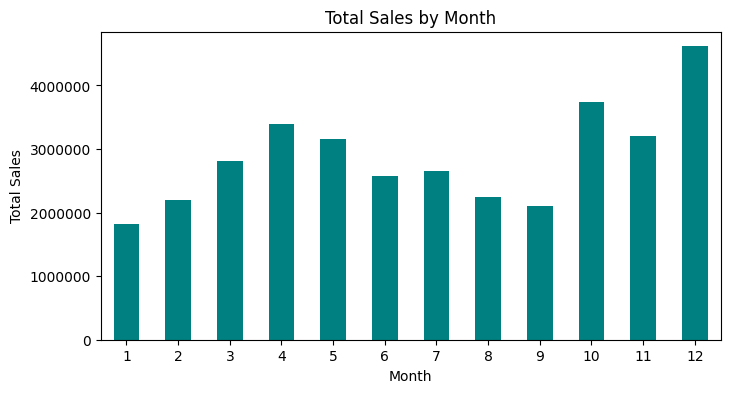

In [80]:
plt.figure(figsize=(8,4))
monthly.plot(kind='bar', color='teal')
plt.title('Total Sales by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.ticklabel_format(style='plain', axis='y')
plt.show()

In [81]:
best_month = monthly.idxmax()
print("Best month:", best_month, "with sales:", monthly.max())

Best month: 12 with sales: 4613443.34


## QUESTION 2 — Which city made the most revenue?

In [82]:
city_sales = df.groupby('City')['Sales'].sum().sort_values(ascending=False)
print(city_sales)

City
San Francisco    8262203.91
Los Angeles      5452570.80
New York City    4664317.43
Boston           3661642.01
Atlanta          2795498.58
Dallas           2767975.40
Seattle          2747755.48
Portland         2320490.61
Austin           1819581.75
Name: Sales, dtype: float64


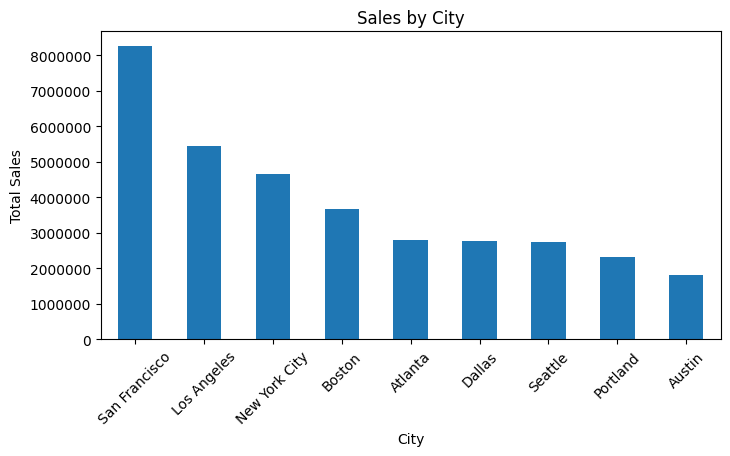

In [83]:
plt.figure(figsize=(8,4))
city_sales.plot(kind='bar')
plt.title('Sales by City')
plt.xlabel('City')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain', axis='y')
plt.show()

In [84]:
best_city = city_sales.idxmax()
print("Highest Revenue City:", best_city, "with sales:", city_sales.max())

Highest Revenue City: San Francisco with sales: 8262203.91


## QUESTION 3 — What time (hour) should ads be shown to maximize sales?

In [85]:
hourly = df.groupby('Hour')['Sales'].sum().sort_values(ascending=False)
print(hourly)

Hour
19    2412938.54
12    2316821.34
11    2300610.24
20    2281716.24
18    2219348.30
13    2155389.80
17    2129361.61
14    2083672.73
21    2042000.86
10    1944286.77
15    1941549.60
16    1904601.31
9     1639030.58
22    1607549.21
8     1192348.97
23    1179304.44
7      744854.12
0      713721.27
1      460866.88
6      448113.00
2      234851.44
5      230679.82
4      162661.01
3      145757.89
Name: Sales, dtype: float64


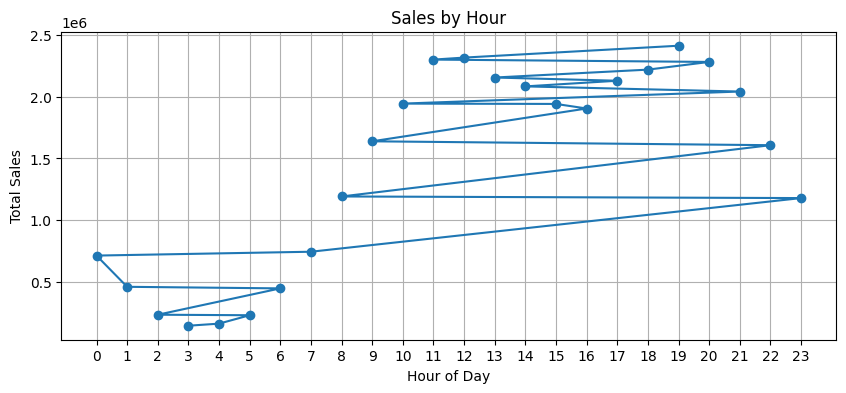

In [86]:
plt.figure(figsize=(10,4))
hourly.plot(kind='line', marker='o')
plt.title('Sales by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Total Sales')
plt.xticks(range(0,24))
plt.grid(True)
plt.show()

In [87]:
best_hour = hourly.idxmax()
print("Best hour to show ads:", best_hour)

Best hour to show ads: 19


## QUESTION 4 — Which product sold the most (by quantity) and by revenue?

In [88]:
qty_by_prod = df.groupby('Product')['Quantity Ordered'].sum().sort_values(ascending=False)
rev_by_prod = df.groupby('Product')['Sales'].sum().sort_values(ascending=False)

print("Top products by quantity:\n", qty_by_prod)
print("\nTop products by revenue:\n", rev_by_prod)

Top products by quantity:
 Product
AAA Batteries (4-pack)        31017
AA Batteries (4-pack)         27635
USB-C Charging Cable          23975
Lightning Charging Cable      23217
Wired Headphones              20557
Apple Airpods Headphones      15661
Bose SoundSport Headphones    13457
27in FHD Monitor               7550
iPhone                         6849
27in 4K Gaming Monitor         6244
34in Ultrawide Monitor         6199
Google Phone                   5532
Flatscreen TV                  4819
Macbook Pro Laptop             4728
ThinkPad Laptop                4130
20in Monitor                   4129
Vareebadd Phone                2068
LG Washing Machine              666
LG Dryer                        646
Name: Quantity Ordered, dtype: int64

Top products by revenue:
 Product
Macbook Pro Laptop            8037600.00
iPhone                        4794300.00
ThinkPad Laptop               4129958.70
Google Phone                  3319200.00
27in 4K Gaming Monitor        2435097.56
34in

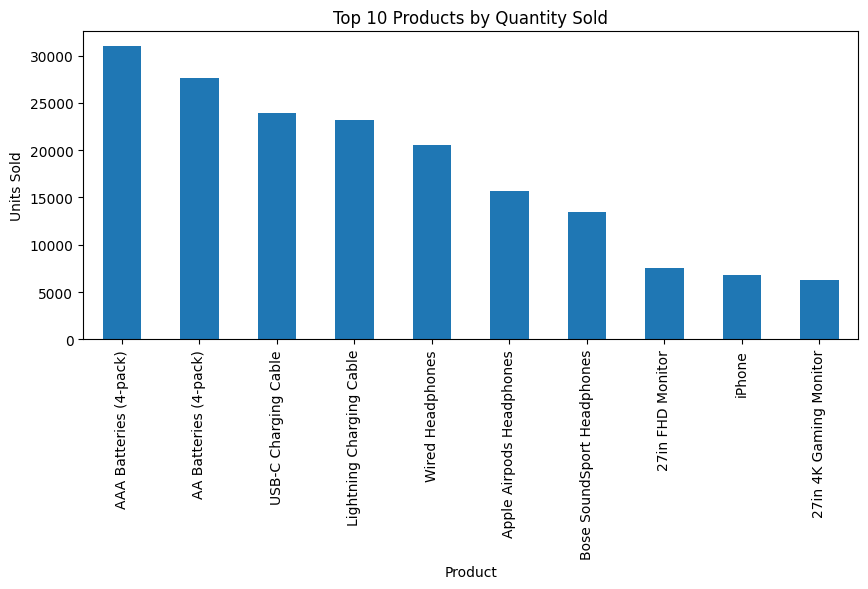

In [89]:
plt.figure(figsize=(10,4))
qty_by_prod.head(10).plot(kind='bar')
plt.title('Top 10 Products by Quantity Sold')
plt.ylabel('Units Sold')
plt.show()

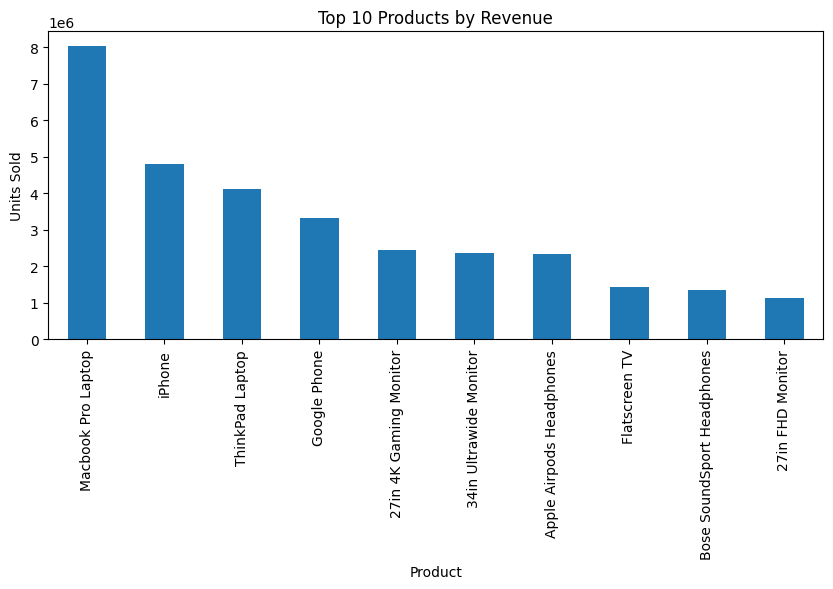

In [90]:
plt.figure(figsize=(10,4))
rev_by_prod.head(10).plot(kind='bar')
plt.title('Top 10 Products by Revenue')
plt.ylabel('Units Sold')
plt.show()

## QUESTION 5 — Relationship between price and sales volume

In [91]:
# average price per product vs quantity sold
price_avg = df.groupby('Product')['Price Each'].mean()
qty = df.groupby('Product')['Quantity Ordered'].sum()
price_vs_qty = pd.concat([price_avg, qty], axis=1).rename(columns={'Price Each':'AvgPrice', 'Quantity Ordered':'TotalQty'})
price_vs_qty

,AvgPrice,TotalQty
Product,,
20in Monitor,109.99,4129
27in 4K Gaming Monitor,389.99,6244
27in FHD Monitor,149.99,7550
34in Ultrawide Monitor,379.99,6199
AA Batteries (4-pack),3.84,27635
AAA Batteries (4-pack),2.99,31017
Apple Airpods Headphones,150.00,15661
Bose SoundSport Headphones,99.99,13457
Flatscreen TV,300.00,4819


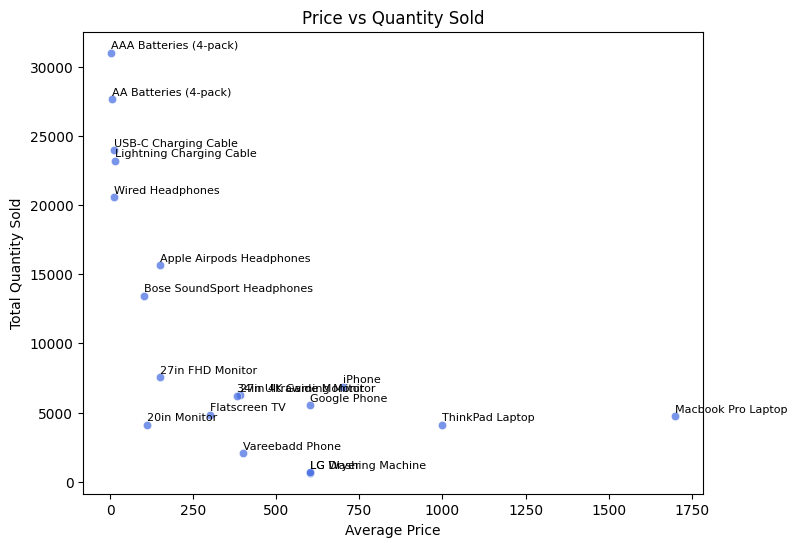

In [92]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='AvgPrice', y='TotalQty', data=price_vs_qty, color='royalblue', alpha=0.7)
for i in price_vs_qty.index:
    x = price_vs_qty.loc[i, 'AvgPrice']
    y = price_vs_qty.loc[i, 'TotalQty']
    plt.text(x, y + 300, i, fontsize=8)
plt.xlabel('Average Price')
plt.ylabel('Total Quantity Sold')
plt.title('Price vs Quantity Sold')
plt.show()

## QUESTION 6 — City with highest average order value

In [93]:
aov = df.groupby('City')['Sales'].mean().sort_values(ascending=False)
print(aov)

City
Atlanta          187.856903
New York City    187.502711
Dallas           186.772969
Seattle          186.516120
Portland         186.160498
San Francisco    184.704550
Los Angeles      184.177362
Austin           183.703357
Boston           183.688272
Name: Sales, dtype: float64


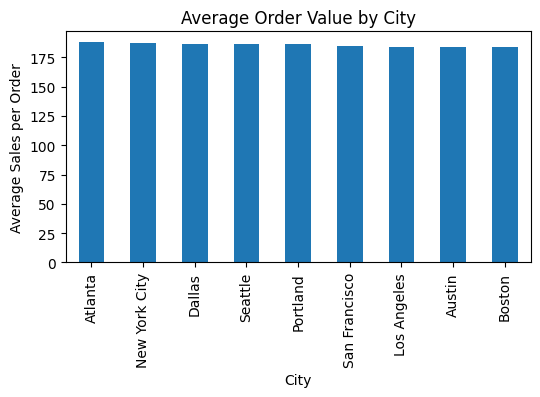

In [94]:
plt.figure(figsize=(6,3))
aov.plot(kind='bar')
plt.title('Average Order Value by City')
plt.ylabel('Average Sales per Order')
plt.show()

## QUESTION 7 — How do sales vary across days of week?

In [95]:
weekday_sales = df.groupby('Weekday')['Sales'].sum().reindex(
    ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
)
print(weekday_sales)

Weekday
Monday       4883326.72
Tuesday      5087956.78
Wednesday    4988822.26
Thursday     4839465.16
Friday       4855938.38
Saturday     4904357.01
Sunday       4932169.66
Name: Sales, dtype: float64


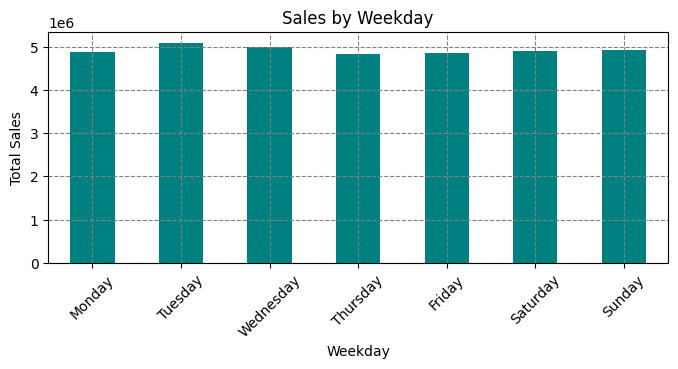

In [96]:
plt.figure(figsize=(8,3))
weekday_sales.plot(kind='bar', color='teal')
plt.title('Sales by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Total Sales')
plt.grid(True, linestyle='--', color='gray')
plt.xticks(rotation=45)
plt.show()

## QUESTION 8 — Top product combinations (products frequently bought together)

In [97]:
# Consider orders where Order ID has multiple products
df_dup = df[df['Order ID'].duplicated(keep=False)].copy()
df_dup['Grouped'] = df_dup.groupby('Order ID')['Product'].transform(lambda x: ', '.join(x))
grouped = df_dup[['Order ID','Grouped']].drop_duplicates()
grouped

,Order ID,Grouped
16,295681,"Google Phone, USB-C Charging Cable, Bose Sound..."
36,295698,"Vareebadd Phone, USB-C Charging Cable"
42,295703,"AA Batteries (4-pack), Bose SoundSport Headphones"
66,295726,"iPhone, Lightning Charging Cable"
76,295735,"iPhone, Apple Airpods Headphones, Wired Headph..."
...,...,...
185898,222863,"27in FHD Monitor, Bose SoundSport Headphones"
185904,222868,"iPhone, Apple Airpods Headphones"
185919,222882,"Apple Airpods Headphones, AA Batteries (4-pack)"
185922,222884,"Google Phone, USB-C Charging Cable"


In [98]:
count = Counter()
for items in grouped['Grouped']:
    products = items.split(',')
    # count all 2-product combinations
    for combo in combinations(sorted(products), 2):
        count[combo] += 1

most_common = count.most_common(10)

# Convert to DataFrame for a clean view
pairs_df = pd.DataFrame(most_common, columns=['Product Pair', 'Count'])

# Split tuple pairs into two columns (optional but clearer)
pairs_df[['Product 1', 'Product 2']] = pd.DataFrame(pairs_df['Product Pair'].tolist(), index=pairs_df.index)
pairs_df = pairs_df[['Product 1', 'Product 2', 'Count']]

print("\nTop 10 Most Common Product Pairs:\n")
print(pairs_df.to_string(index=False))


Top 10 Most Common Product Pairs:

                  Product 1         Product 2  Count
   Lightning Charging Cable            iPhone   1005
       USB-C Charging Cable      Google Phone    987
           Wired Headphones            iPhone    447
           Wired Headphones      Google Phone    414
       USB-C Charging Cable   Vareebadd Phone    361
   Apple Airpods Headphones            iPhone    360
 Bose SoundSport Headphones      Google Phone    220
           Wired Headphones   Vareebadd Phone    143
       USB-C Charging Cable  Wired Headphones    123
 Bose SoundSport Headphones   Vareebadd Phone     80


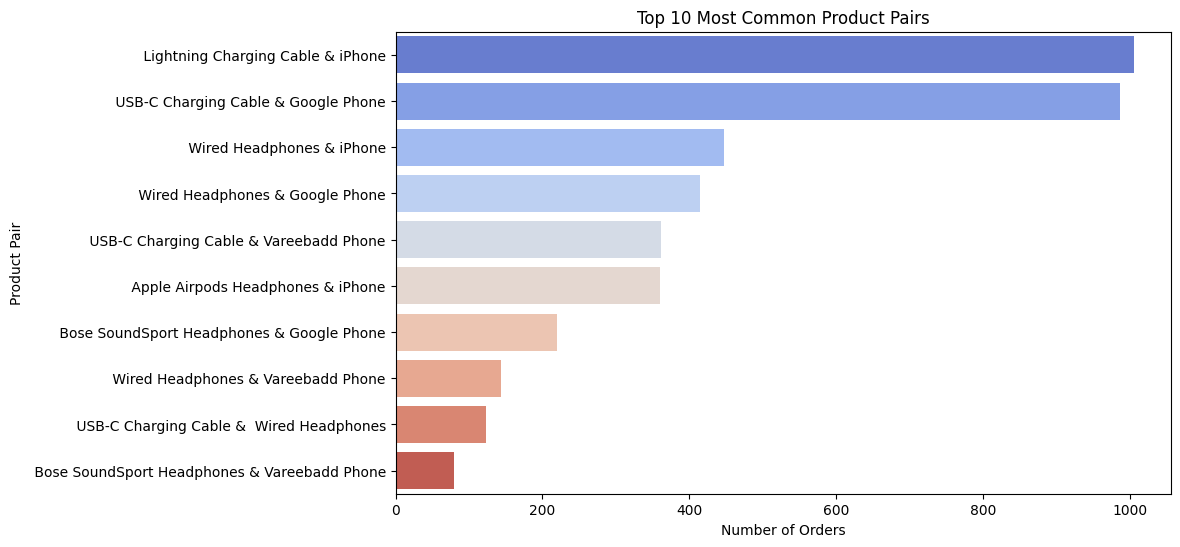

In [99]:
pairs_df['Product Pair'] = pairs_df['Product 1'] + ' & ' + pairs_df['Product 2']

plt.figure(figsize=(10,6))
sns.barplot(x='Count', y='Product Pair', hue='Product Pair', data=pairs_df, palette='coolwarm')
plt.title('Top 10 Most Common Product Pairs')
plt.xlabel('Number of Orders')
plt.ylabel('Product Pair')
plt.show()

## QUESTION 9 — Which products perform best in each city?

In [100]:
city_product = df.groupby(['City','Product'])['Sales'].sum().reset_index()
top_city_products = city_product.sort_values(['City','Sales'], ascending=[True,False]).groupby('City').head(5)
top_city_products

,City,Product,Sales
13,Atlanta,Macbook Pro Laptop,644300.00
18,Atlanta,iPhone,380800.00
14,Atlanta,ThinkPad Laptop,356996.43
9,Atlanta,Google Phone,270600.00
1,Atlanta,27in 4K Gaming Monitor,192265.07
32,Austin,Macbook Pro Laptop,426700.00
37,Austin,iPhone,263900.00
33,Austin,ThinkPad Laptop,209997.90
28,Austin,Google Phone,164400.00
25,Austin,Apple Airpods Headphones,133050.00


In [101]:
# display as pivot for readability
pivot = top_city_products.pivot(index='Product', columns='City', values='Sales').fillna(0)
pivot.head()

City,Atlanta,Austin,Boston,Dallas,Los Angeles,New York City,Portland,San Francisco,Seattle
Product,,,,,,,,,
27in 4K Gaming Monitor,192265.07,0.0,263243.25,0.00,391159.97,0.00,169255.66,569385.4,209814.62
34in Ultrawide Monitor,0.00,0.0,0.00,194554.88,0.00,329831.32,0.00,0.0,0.00
Apple Airpods Headphones,0.00,133050.0,0.00,0.00,0.00,0.00,0.00,0.0,0.00
Google Phone,270600.00,164400.0,355800.00,276600.00,508800.00,454800.00,213000.00,814800.0,260400.00
Macbook Pro Laptop,644300.00,426700.0,814300.00,649400.00,1276700.00,1116900.00,572900.00,1931200.0,605200.00


In [102]:
pivot_style = pivot.style.background_gradient(cmap='coolwarm').format('${:,.0f}')
pivot_style

City,Atlanta,Austin,Boston,Dallas,Los Angeles,New York City,Portland,San Francisco,Seattle
Product,,,,,,,,,
27in 4K Gaming Monitor,"$192,265",$0,"$263,243",$0,"$391,160",$0,"$169,256","$569,385","$209,815"
34in Ultrawide Monitor,$0,$0,$0,"$194,555",$0,"$329,831",$0,$0,$0
Apple Airpods Headphones,$0,"$133,050",$0,$0,$0,$0,$0,$0,$0
Google Phone,"$270,600","$164,400","$355,800","$276,600","$508,800","$454,800","$213,000","$814,800","$260,400"
Macbook Pro Laptop,"$644,300","$426,700","$814,300","$649,400","$1,276,700","$1,116,900","$572,900","$1,931,200","$605,200"
ThinkPad Laptop,"$356,996","$209,998","$446,996","$344,997","$640,994","$559,994","$273,997","$962,990","$332,997"
iPhone,"$380,800","$263,900","$527,100","$363,300","$782,600","$616,700","$315,000","$1,162,700","$382,200"


## QUESTION 10 — Total yearly sales & simple growth (if multiple years)

In [103]:
df['Year'] = df['Order Date'].dt.year
yearly = df.groupby('Year')['Sales'].sum()
print(yearly)

Year
2019    34483365.68
2020        8670.29
Name: Sales, dtype: float64


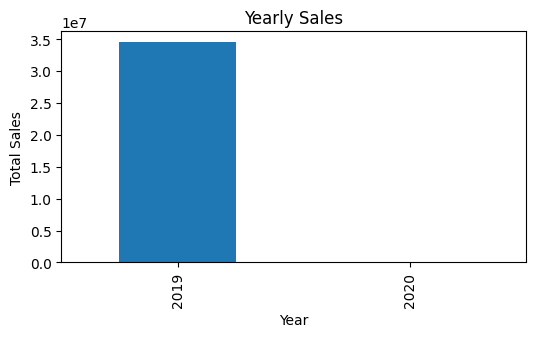

In [104]:
plt.figure(figsize=(6,3))
yearly.plot(kind='bar')
plt.title('Yearly Sales')
plt.ylabel('Total Sales')
plt.show()

In [105]:
# simple growth rate (if >1 year)
if len(yearly) > 1:
    growth = yearly.pct_change().dropna()
    print("Year over Year growth:\n", growth)

Year over Year growth:
 Year
2020   -0.999749
Name: Sales, dtype: float64


Showing because there is data of only a year.

## Save key outputs

In [106]:
monthly.to_csv('Sales Analysis Results/monthly_sales.csv')
city_sales.to_csv('Sales Analysis Results/city_sales.csv')
qty_by_prod.head(20).to_csv('Sales Analysis Results/top_products_by_qty.csv')
pd.DataFrame(most_common, columns=['Product Pair','Count']).to_csv('Sales Analysis Results/top_product_pairs.csv', index=False)

## Short summary

In [107]:
print("Top month:", monthly.idxmax(), ", Sales:", monthly.max())
print("Top city:", city_sales.idxmax(), ", Sales:", city_sales.max())
print("Best hour:", hourly.idxmax())
print("Top product by revenue:", rev_by_prod.idxmax(), rev_by_prod.max())

Top month: 12 , Sales: 4613443.34
Top city: San Francisco , Sales: 8262203.91
Best hour: 19
Top product by revenue: Macbook Pro Laptop 8037600.0


# Train the Forecasting Model

In [108]:
monthly_sales = df.groupby('Month')['Sales'].sum().reset_index()
print(monthly_sales)

# Prepare data
X = monthly_sales['Month'].values.reshape(-1, 1)
y = monthly_sales['Sales'].values

# Train model
model = LinearRegression()
model.fit(X, y)

# Predict next 3 months (13, 14, 15)
future_months = np.array([13, 14, 15]).reshape(-1, 1)
predicted_sales = model.predict(future_months)

    Month       Sales
0       1  1822256.73
1       2  2202022.42
2       3  2807100.38
3       4  3390670.24
4       5  3152606.75
5       6  2577802.26
6       7  2647775.76
7       8  2244467.88
8       9  2097560.13
9      10  3736726.88
10     11  3199603.20
11     12  4613443.34


In [109]:
for month, sales in zip(future_months.flatten(), predicted_sales):
    print(f"Predicted Sales for Month {month}: ${sales:,.2f}")

Predicted Sales for Month 13: $3,716,806.14
Predicted Sales for Month 14: $3,846,416.88
Predicted Sales for Month 15: $3,976,027.62


## Visualize the Forecast

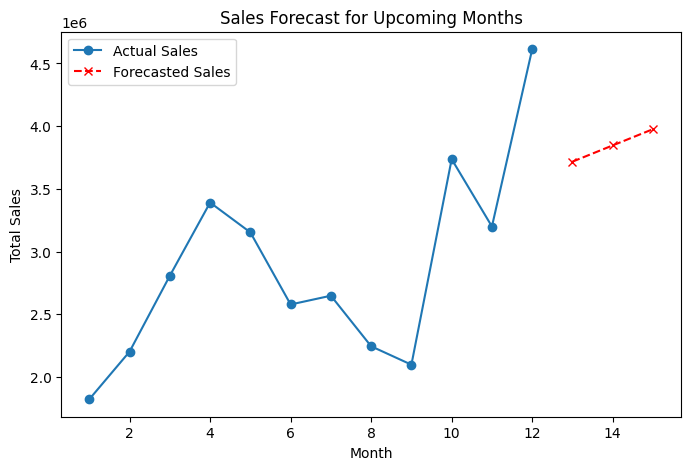

In [110]:
plt.figure(figsize=(8, 5))
plt.plot(X, y, marker='o', label='Actual Sales')
plt.plot(future_months, predicted_sales, marker='x', linestyle='--', color='red', label='Forecasted Sales')
plt.title("Sales Forecast for Upcoming Months")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.legend()
plt.show()